# ESP card-guessing experiment: analysis notebook
**NS203 — Assignment 2**

This notebook analyses 40 card guesses from each of five participants (P1–P5).
The sender attempted to mentally transmit **rank only**, while receivers guessed rank and suit during remote calls.
The experiment used software-generated pseudorandom targets and the same target sequence for all five participants.

**Question:** Does any participant match the target rank more often than expected under shuffled target–response pairing?

Rank matching is the **primary outcome**. Suit and complete-card matching are exploratory. The analysis choices were made after collection, not preregistered.

### How to run
1. Open this file in Jupyter Notebook, JupyterLab, or VS Code.
2. Select a Python kernel and choose **Restart Kernel and Run All Cells**.
3. Read the tables and figures directly below their code cells.

The original data are embedded below, so no CSV download or path editing is needed. The last section also saves results into an `esp_outputs` folder beside the notebook's working directory.

Required packages: `numpy`, `pandas`, `scipy`, and `matplotlib`.
If needed, install them in your environment with `pip install numpy pandas scipy matplotlib`.

## 1. Import the packages and set a few choices

`pandas` organises tables, `numpy` handles numerical arrays and random shuffling,
`scipy` supplies normal quantiles and an optional binomial benchmark, and `matplotlib` draws figures.
A fixed seed makes the Monte Carlo analysis repeatable. We use the same 100,000 permutations and seed as the report.

In [1]:
from io import StringIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, binomtest

participants = ["P1", "P2", "P3", "P4", "P5"]
ranks = ["A", "2", "3", "4", "5", "6", "7", "8", "9", "10", "J", "Q", "K"]
suit_names = {1: "Hearts", 2: "Diamonds", 3: "Spades", 4: "Clubs"}
outcomes = ["rank", "suit", "full_card"]

number_of_permutations = 100_000
random_seed = 2032026
alpha = 0.05

output_folder = Path("esp_outputs")
output_folder.mkdir(exist_ok=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"font.size": 10, "figure.dpi": 130})

## 2. Enter the original data

Each row is one trial. `TRUE` is the target card; P1–P5 are the five guesses.
The **last digit** is suit and the **prefix** is rank: `103` means 10 of spades, and `J2` means Jack of diamonds.

Two confirmed coding decisions are used later:
- Numeric rank `1` means Ace, equivalent to `A`.
- P4's `Q04` on trial 8 means `Q4`.

The original table below is kept unchanged. Corrections are applied only while parsing it.

In [2]:
card_data = """
TRUE,P1,P2,P3,P4,P5
A1,J3,K1,71,A2,73
41,Q1,72,J2,31,J3
23,62,43,83,103,22
A4,A3,12,J4,33,104
41,Q1,13,81,K1,K4
J2,Q1,32,K3,54,Q1
J3,J4,83,84,A3,52
84,13,32,K1,Q04,84
24,21,33,Q2,K1,J2
21,102,K2,31,32,A3
Q1,34,21,A3,63,51
63,53,Q1,84,73,102
22,71,J2,J3,32,84
23,K3,Q1,34,22,K4
93,91,J3,41,K4,103
24,J3,Q3,72,42,A2
J2,K4,72,21,81,K2
J1,Q1,K3,A4,53,A4
81,A3,92,93,73,33
K4,J4,23,102,81,Q4
81,52,A2,63,94,41
A1,61,A3,Q1,Q4,23
24,A1,A1,A2,A2,J4
62,52,A2,74,K3,81
31,31,103,82,K3,104
A3,32,32,K4,22,A1
J4,84,91,54,103,54
J1,72,K4,103,J4,93
33,13,34,22,53,Q1
A4,43,J4,23,51,J3
22,41,K4,K2,92,61
101,31,62,21,43,23
Q2,K4,K4,33,31,Q2
81,21,62,52,84,K3
23,23,14,81,K1,A2
84,64,22,74,J4,33
J4,J2,34,51,A3,J1
52,71,52,42,62,102
K3,64,J4,93,61,J4
43,A1,12,41,72,A2
"""

raw_data = pd.read_csv(StringIO(card_data), dtype=str)
number_of_trials = len(raw_data)

print(f"{number_of_trials} shared targets; {len(participants)} participants.")
display(raw_data.head(10))

40 shared targets; 5 participants.


,TRUE,P1,P2,P3,P4,P5
0,A1,J3,K1,71,A2,73
1,41,Q1,72,J2,31,J3
2,23,62,43,83,103,22
3,A4,A3,12,J4,33,104
4,41,Q1,13,81,K1,K4
5,J2,Q1,32,K3,54,Q1
6,J3,J4,83,84,A3,52
7,84,13,32,K1,Q04,84
8,24,21,33,Q2,K1,J2
9,21,102,K2,31,32,A3


## 3. Separate each card into rank and suit

This small function reads a card code. It also checks that the rank and suit are valid.
For example, `parse_card("103")` returns `("10", 3)`.

The parser does **not** modify `raw_data`.

In [3]:
def parse_card(card_code):
    """Return the rank and suit of one recorded card code."""
    card_code = card_code.strip().upper()

    if card_code == "Q04":
        card_code = "Q4"  # Confirmed transcription correction.

    rank = card_code[:-1]
    suit = int(card_code[-1])

    if rank == "1":
        rank = "A"

    if rank not in ranks or suit not in suit_names:
        raise ValueError(f"Invalid card code: {card_code}")

    return rank, suit

print("Example:", parse_card("103"))
print("Ace alias:", parse_card("13"))
print("Confirmed correction:", parse_card("Q04"))

Example: ('10', 3)
Ace alias: ('A', 3)
Confirmed correction: ('Q', 4)


## 4. Make one tidy table of all 200 responses

One row now represents **one participant's response on one trial**.
We score three outcomes separately:

| Outcome | A correct response requires |
|---|---|
| Rank | Correct rank, regardless of suit |
| Suit | Correct suit, regardless of rank |
| Full card | Both correct rank and correct suit |

For example, Queen of clubs is a correct **rank** guess for Queen of hearts, but is not a complete-card match.

In [4]:
response_rows = []

for trial_index in range(number_of_trials):
    target_code = raw_data.loc[trial_index, "TRUE"]
    target_rank, target_suit = parse_card(target_code)

    for participant in participants:
        guess_code = raw_data.loc[trial_index, participant]
        guessed_rank, guessed_suit = parse_card(guess_code)

        rank_correct = guessed_rank == target_rank
        suit_correct = guessed_suit == target_suit

        response_rows.append({
            "trial": trial_index + 1,
            "participant": participant,
            "target_raw": target_code,
            "response_raw": guess_code,
            "target_rank": target_rank,
            "target_suit": target_suit,
            "response_rank": guessed_rank,
            "response_suit": guessed_suit,
            "rank_correct": rank_correct,
            "suit_correct": suit_correct,
            "full_card_correct": rank_correct and suit_correct,
        })

responses = pd.DataFrame(response_rows)

assert len(responses) == 200
assert responses.groupby("participant").size().eq(40).all()
display(responses.head(10))

,trial,participant,target_raw,response_raw,target_rank,target_suit,response_rank,response_suit,rank_correct,suit_correct,full_card_correct
0,1,P1,A1,J3,A,1,J,3,False,False,False
1,1,P2,A1,K1,A,1,K,1,False,True,False
2,1,P3,A1,71,A,1,7,1,False,True,False
3,1,P4,A1,A2,A,1,A,2,True,False,False
4,1,P5,A1,73,A,1,7,3,False,False,False
5,2,P1,41,Q1,4,1,Q,1,False,True,False
6,2,P2,41,72,4,1,7,2,False,False,False
7,2,P3,41,J2,4,1,J,2,False,False,False
8,2,P4,41,31,4,1,3,1,False,True,False
9,2,P5,41,J3,4,1,J,3,False,False,False


## 5. Count target ranks and preferred guesses

Unequal target frequencies can occur in a short random sequence; they do not by themselves indicate faulty randomization.
However, frequencies matter when interpreting matching scores. A person who repeatedly guesses a common target rank can get some matches without trial-specific information.

Count the **40 shared targets once**, not 200 times. Rank 7 is included even though it never occurred.

In [5]:
target_cards = responses[responses["participant"] == "P1"].copy()

rank_frequencies = pd.DataFrame(index=ranks)
rank_frequencies.index.name = "rank"
rank_frequencies["target_count"] = (
    target_cards["target_rank"].value_counts().reindex(ranks, fill_value=0)
)

for participant in participants:
    guesses = responses[responses["participant"] == participant]
    rank_frequencies[f"{participant}_guess_count"] = (
        guesses["response_rank"].value_counts().reindex(ranks, fill_value=0)
    )

display(rank_frequencies)

,target_count,P1_guess_count,P2_guess_count,P3_guess_count,P4_guess_count,P5_guess_count
rank,,,,,,
A,5,6,8,3,4,6
2,9,3,3,4,2,3
3,2,4,6,3,5,2
4,3,2,1,3,2,1
5,1,3,1,3,4,3
6,2,4,2,1,3,1
7,0,3,2,4,3,1
8,5,1,1,6,3,3
9,1,1,2,2,2,1


## 6. Calculate accuracy and its uncertainty

Accuracy is the number of matches divided by 40.
We use **95% Wilson intervals** to describe uncertainty in each participant's accuracy.
These are marginal intervals under an independent-trial model, not intervals adjusted for multiple tests.
They should not be used in place of the permutation tests below.

In the function, $\hat p=k/n$, $z=\Phi^{-1}(0.975)$, and the Wilson interval is its centre plus/minus its half-width.

In [6]:
def wilson_interval(correct, total):
    """Return the lower and upper bounds of a 95% Wilson interval."""
    proportion = correct / total
    z = norm.ppf(0.975)
    denominator = 1 + z**2 / total

    centre = (proportion + z**2 / (2 * total)) / denominator
    half_width = (
        z * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2))
        / denominator
    )
    return centre - half_width, centre + half_width

summary_rows = []

for participant in participants:
    participant_data = responses[responses["participant"] == participant]

    for outcome in outcomes:
        correct = int(participant_data[f"{outcome}_correct"].sum())
        total = len(participant_data)
        lower, upper = wilson_interval(correct, total)

        summary_rows.append({
            "participant": participant,
            "outcome": outcome,
            "n": total,
            "correct": correct,
            "accuracy": correct / total,
            "ci95_low": lower,
            "ci95_high": upper,
        })

accuracy_summary = pd.DataFrame(summary_rows)
display(accuracy_summary)

,participant,outcome,n,correct,accuracy,ci95_low,ci95_high
0,P1,rank,40,7,0.175,0.0875,0.3195
1,P1,suit,40,15,0.375,0.2422,0.5297
2,P1,full_card,40,2,0.050,0.0138,0.1650
3,P2,rank,40,4,0.100,0.0396,0.2305
4,P2,suit,40,12,0.300,0.1807,0.4543
5,P2,full_card,40,1,0.025,0.0044,0.1288
6,P3,rank,40,1,0.025,0.0044,0.1288
7,P3,suit,40,12,0.300,0.1807,0.4543
8,P3,full_card,40,0,0.000,0.0000,0.0876
9,P4,rank,40,4,0.100,0.0396,0.2305


## 7. Prepare arrays for target shuffling

The null hypothesis tested here is that target–response pairing is exchangeable: there is no trial-specific association that increases matching.
Shuffling keeps the actual target frequencies and guesses unchanged, but breaks their trial-by-trial alignment.

**Important assumptions:** feedback, time trends, learning, or sequence structure could make unrestricted shuffling inappropriate. The software's sampling rule and feedback procedure remain to be documented.

We shuffle **complete cards**, so rank and suit stay together. The same shuffled target sequence is compared with all five participants.

The target arrays have 40 entries. Each response array has 40 rows (trials) and five columns (participants).

In [7]:
target_ranks = target_cards["target_rank"].to_numpy()
target_suits = target_cards["target_suit"].to_numpy()

response_ranks = np.column_stack([
    responses.loc[responses["participant"] == participant, "response_rank"].to_numpy()
    for participant in participants
])
response_suits = np.column_stack([
    responses.loc[responses["participant"] == participant, "response_suit"].to_numpy()
    for participant in participants
])

# One array per outcome: rows = permutations; columns = participants.
null_counts = {}
for outcome in outcomes:
    null_counts[outcome] = np.zeros(
        (number_of_permutations, len(participants)), dtype=int
    )

print("Targets:", target_ranks.shape)
print("Responses:", response_ranks.shape)

Targets: (40,)
Responses: (40, 5)


## 8. Run the permutation experiment

For each repetition:
1. Assign a random number to each target and sort those numbers to produce a random order.
2. Reorder both target ranks and suits using that same order.
3. Count rank, suit, and full-card matches for all five participants.

Sorting random keys is just a way to generate a random permutation. It is retained here so the random-number sequence reproduces the earlier script's report values exactly.
The `[:, None]` expression turns the 40 targets into one column, letting NumPy compare them with all five response columns.

This cell may take a little time because it performs 100,000 repetitions. It does not create new experimental observations.

In [8]:
rng = np.random.default_rng(random_seed)

for permutation_index in range(number_of_permutations):
    shuffled_order = np.argsort(rng.random(number_of_trials))
    shuffled_ranks = target_ranks[shuffled_order]
    shuffled_suits = target_suits[shuffled_order]

    rank_matches = response_ranks == shuffled_ranks[:, None]
    suit_matches = response_suits == shuffled_suits[:, None]
    full_card_matches = rank_matches & suit_matches

    # Sum down the trial rows, leaving one count per participant.
    null_counts["rank"][permutation_index] = rank_matches.sum(axis=0)
    null_counts["suit"][permutation_index] = suit_matches.sum(axis=0)
    null_counts["full_card"][permutation_index] = full_card_matches.sum(axis=0)

print(f"Completed {number_of_permutations:,} target permutations.")

Completed 100,000 target permutations.


## 9. Calculate one-sided permutation p-values

For each participant and outcome, count how many null scores are **at least as large as** the observed score:

$$p=\frac{b+1}{B+1}.$$

Here $b$ is the number of null counts at least as large as observed and $B$ is the number of permutations.
Adding one prevents zero Monte Carlo p-values (Phipson & Smyth, 2010).

This is a test of **above-null matching**. A large p-value is not proof of no ability and does not test below-chance performance.

In [9]:
permutation_pvalues = []
permutation_means = []

for row in accuracy_summary.itertuples(index=False):
    participant_index = participants.index(row.participant)
    null_scores = null_counts[row.outcome][:, participant_index]

    extreme_count = np.count_nonzero(null_scores >= row.correct)
    pvalue = (extreme_count + 1) / (number_of_permutations + 1)

    permutation_pvalues.append(pvalue)
    permutation_means.append(null_scores.mean())

accuracy_summary["permutation_expected_correct"] = permutation_means
accuracy_summary["permutation_p_greater"] = permutation_pvalues

display(accuracy_summary[[
    "participant", "outcome", "correct", "accuracy",
    "permutation_expected_correct", "permutation_p_greater"
]])

,participant,outcome,correct,accuracy,permutation_expected_correct,permutation_p_greater
0,P1,rank,7,0.175,3.4444,0.0473
1,P1,suit,15,0.375,10.6143,0.0834
2,P1,full_card,2,0.050,0.9530,0.2467
3,P2,rank,4,0.100,3.5240,0.4754
4,P2,suit,12,0.300,9.2494,0.1909
5,P2,full_card,1,0.025,0.7517,0.5341
6,P3,rank,1,0.025,3.4412,0.9760
7,P3,suit,12,0.300,10.0693,0.2934
8,P3,full_card,0,0.000,0.9700,1.0000
9,P4,rank,4,0.100,2.8276,0.3122


## 10. Correct the five primary rank tests using Holm's method

Testing five participants creates five opportunities for a false positive. Holm's method controls the family-wise error rate across these five tests without assuming they are independent.

The function sorts the p-values, multiplies the smallest by five, the next by four, and so on, and keeps adjusted values non-decreasing in that sorted order.
Suit and complete-card tests are exploratory; none has an unadjusted p-value below .05. They are not treated as additional primary tests.

In [10]:
def holm_adjust(pvalues):
    """Return Holm-adjusted p-values in their original order."""
    pvalues = np.asarray(pvalues, dtype=float)
    sorted_indices = np.argsort(pvalues)
    number_of_tests = len(pvalues)
    adjusted = np.zeros(number_of_tests)
    previous_adjusted = 0.0

    for position, original_index in enumerate(sorted_indices):
        multiplier = number_of_tests - position
        candidate = multiplier * pvalues[original_index]
        previous_adjusted = max(previous_adjusted, candidate)
        adjusted[original_index] = min(1.0, previous_adjusted)

    return adjusted

rank_mask = accuracy_summary["outcome"] == "rank"
rank_pvalues = accuracy_summary.loc[rank_mask, "permutation_p_greater"].to_numpy()

accuracy_summary["holm_primary_5"] = np.nan
accuracy_summary.loc[rank_mask, "holm_primary_5"] = holm_adjust(rank_pvalues)

rank_results = accuracy_summary.loc[rank_mask].copy()
display(rank_results[[
    "participant", "correct", "accuracy",
    "permutation_p_greater", "holm_primary_5"
]])

,participant,correct,accuracy,permutation_p_greater,holm_primary_5
0,P1,7,0.175,0.0473,0.2365
3,P2,4,0.100,0.4754,1.0000
6,P3,1,0.025,0.9760,1.0000
9,P4,4,0.100,0.3122,1.0000
12,P5,5,0.125,0.3091,1.0000


## 11. Figure 1 — Accuracy for all three outcomes

Blue bars show observed accuracy. Error bars are marginal Wilson intervals.
Orange diamonds show the mean under target permutation.
Dashed lines show ideal uniform-guessing references: 1/13 for rank, 1/4 for suit, and 1/52 for a full card.

These reference probabilities are not a claim that target selection was verified as independent uniform sampling with replacement.
Statistical conclusions use the permutation tests and Holm correction.

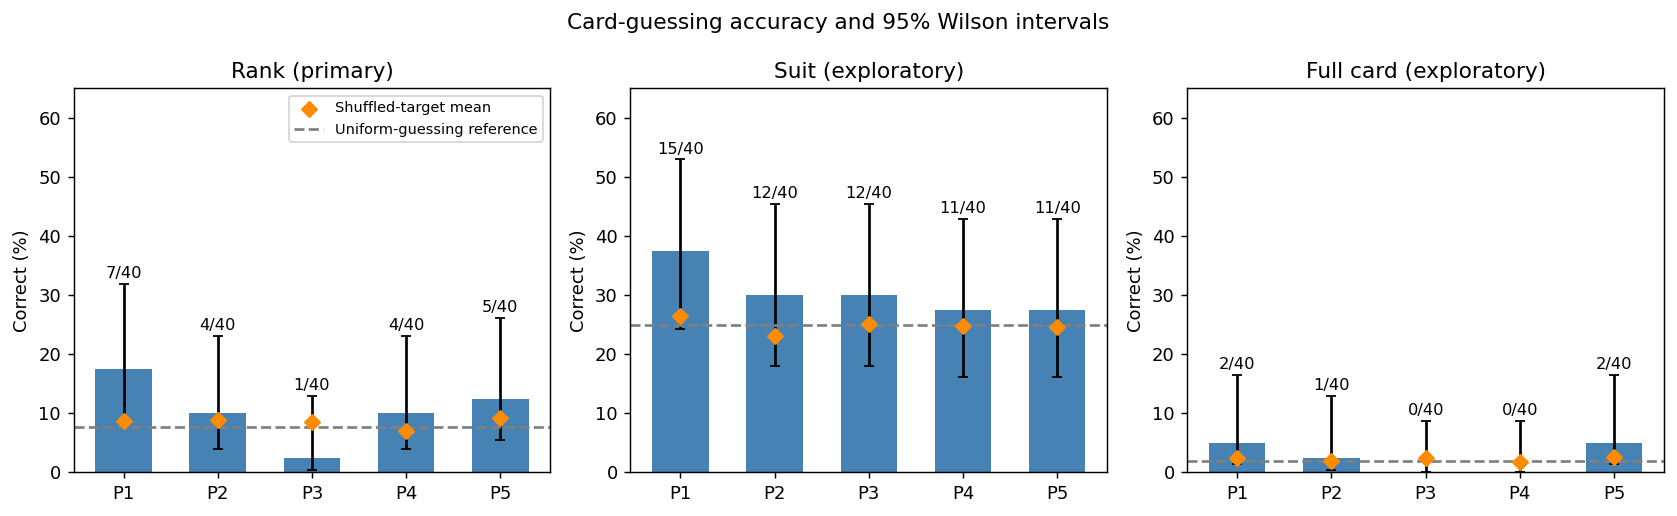

In [11]:
uniform_chance = {"rank": 1 / 13, "suit": 1 / 4, "full_card": 1 / 52}
plot_titles = ["Rank (primary)", "Suit (exploratory)", "Full card (exploratory)"]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
x_positions = np.arange(len(participants))

for outcome, title, ax in zip(outcomes, plot_titles, axes):
    table = accuracy_summary[accuracy_summary["outcome"] == outcome]
    percentages = table["accuracy"].to_numpy() * 100
    lower = table["ci95_low"].to_numpy() * 100
    upper = table["ci95_high"].to_numpy() * 100
    expected = table["permutation_expected_correct"].to_numpy() / number_of_trials * 100

    ax.bar(x_positions, percentages, color="steelblue", width=0.6)
    ax.errorbar(x_positions, percentages,
                yerr=[percentages - lower, upper - percentages],
                fmt="none", color="black", capsize=3)
    ax.scatter(x_positions, expected, marker="D", color="darkorange",
               label="Shuffled-target mean", zorder=3)
    ax.axhline(uniform_chance[outcome] * 100, color="gray", linestyle="--",
               label="Uniform-guessing reference")

    for position, count, top in zip(x_positions, table["correct"], upper):
        ax.text(position, top + 1, f"{count}/40", ha="center", fontsize=9)

    ax.set_xticks(x_positions, participants)
    ax.set_title(title)
    ax.set_ylabel("Correct (%)")
    ax.set_ylim(0, 65)

axes[0].legend(fontsize=8)
fig.suptitle("Card-guessing accuracy and 95% Wilson intervals")
fig.tight_layout()
fig.savefig(output_folder / "accuracy.png", dpi=200, bbox_inches="tight")
fig.savefig(output_folder / "accuracy.pdf", bbox_inches="tight")
plt.show()

## 12. Figure 2 — What scores arise under shuffled pairing?

Each panel shows one participant's null distribution of rank-match counts.
The red line is the observed score. The panel p-values are **unadjusted**.
P1's result must be interpreted using its Holm-adjusted p-value, not the panel value alone.

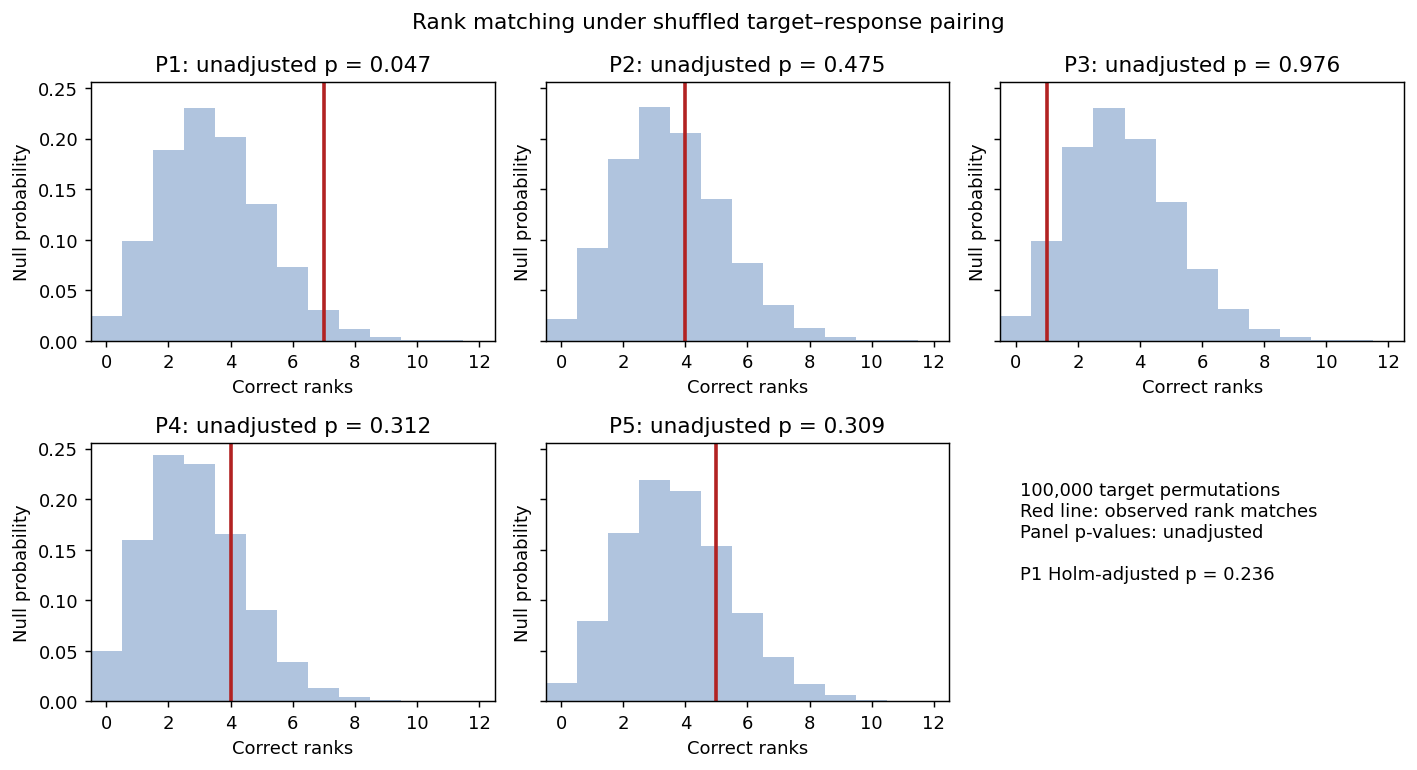

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=True)
axes = axes.ravel()

for participant_index, participant in enumerate(participants):
    ax = axes[participant_index]
    table = rank_results[rank_results["participant"] == participant].iloc[0]
    scores = null_counts["rank"][:, participant_index]
    bins = np.arange(-0.5, scores.max() + 1.5, 1)

    ax.hist(scores, bins=bins, density=True, color="lightsteelblue")
    ax.axvline(table["correct"], color="firebrick", linewidth=2)
    ax.set_title(f"{participant}: unadjusted p = {table['permutation_p_greater']:.3f}")
    ax.set_xlabel("Correct ranks")
    ax.set_ylabel("Null probability")
    ax.set_xticks(np.arange(0, 13, 2))
    ax.set_xlim(-0.5, 12.5)

p1_adjusted = rank_results.loc[rank_results["participant"] == "P1", "holm_primary_5"].iloc[0]
axes[-1].axis("off")
axes[-1].text(0.05, 0.85,
              f"{number_of_permutations:,} target permutations\n"
              "Red line: observed rank matches\n"
              "Panel p-values: unadjusted\n\n"
              f"P1 Holm-adjusted p = {p1_adjusted:.3f}",
              transform=axes[-1].transAxes, va="top")

fig.suptitle("Rank matching under shuffled target–response pairing")
fig.tight_layout()
fig.savefig(output_folder / "rank_permutation.png", dpi=200, bbox_inches="tight")
fig.savefig(output_folder / "rank_permutation.pdf", bbox_inches="tight")
plt.show()

## 13. Figure 3 — Rank confusion matrices

A confusion matrix counts each combination of target rank (row) and guessed rank (column).
The diagonal contains correct rank guesses. Off-diagonal entries are errors.
These matrices show raw counts, not percentages; the empty rank-7 row means that rank was not presented.

All five panels use the same colour scale. The two-row layout makes their labels easier to read in the report.

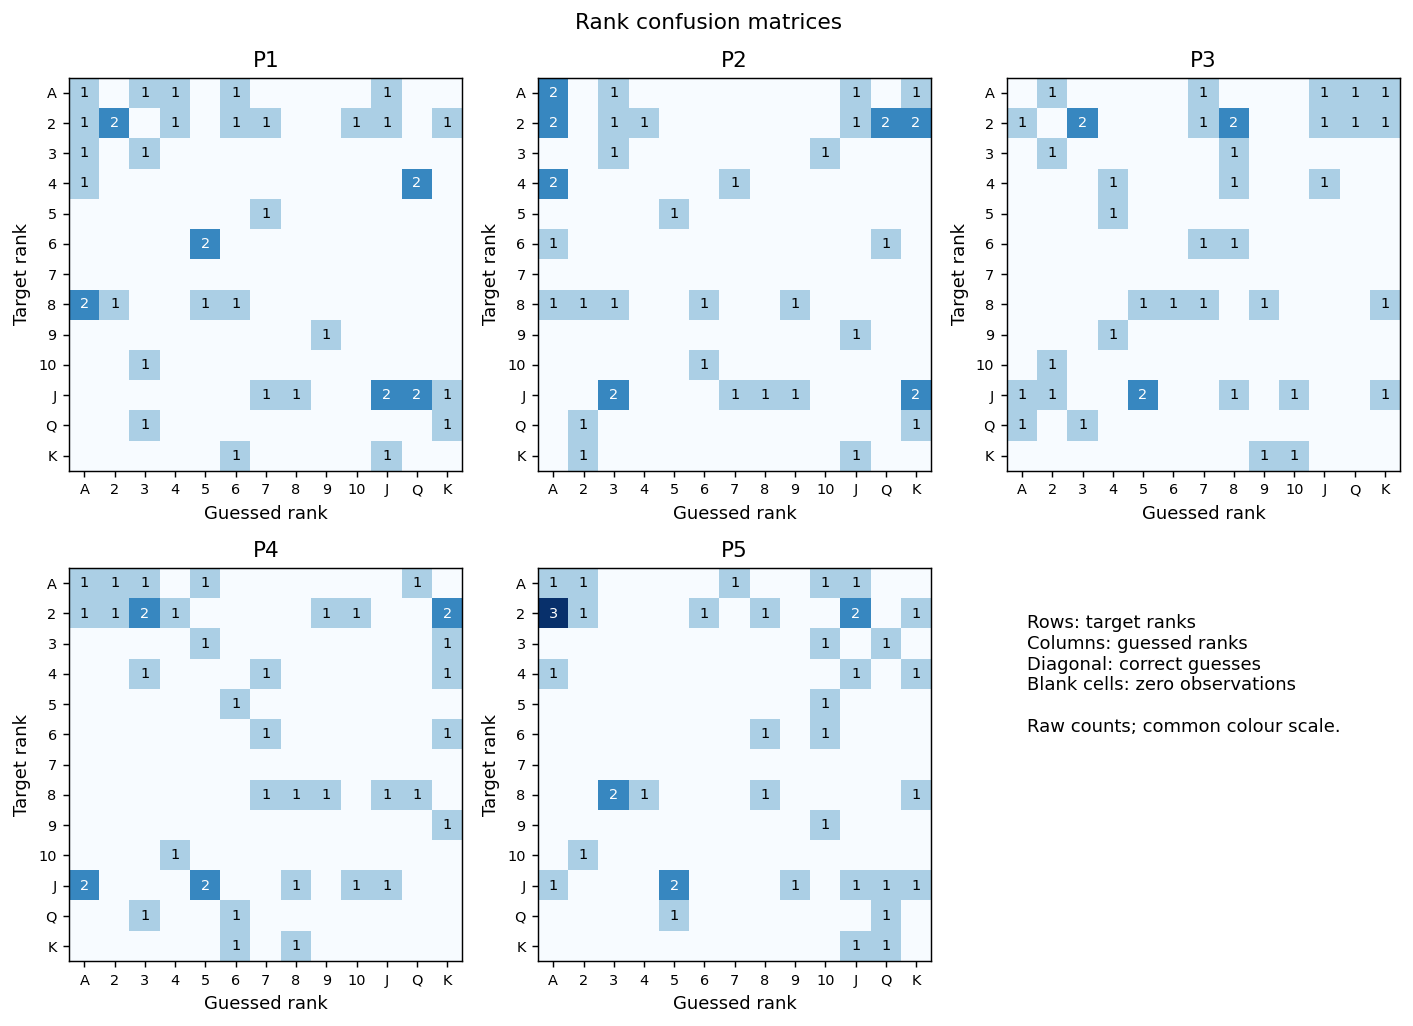

In [13]:
confusion_matrices = {}

for participant in participants:
    participant_data = responses[responses["participant"] == participant]
    matrix = pd.crosstab(participant_data["target_rank"], participant_data["response_rank"])
    matrix = matrix.reindex(index=ranks, columns=ranks, fill_value=0)
    confusion_matrices[participant] = matrix

largest_cell = max(matrix.to_numpy().max() for matrix in confusion_matrices.values())
fig, axes = plt.subplots(2, 3, figsize=(11, 8))
axes = axes.ravel()

for participant_index, participant in enumerate(participants):
    ax = axes[participant_index]
    matrix = confusion_matrices[participant].to_numpy()
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=largest_cell)

    for row_index in range(len(ranks)):
        for column_index in range(len(ranks)):
            count = matrix[row_index, column_index]
            if count > 0:
                colour = "white" if count > largest_cell / 2 else "black"
                ax.text(column_index, row_index, str(count),
                        ha="center", va="center", color=colour, fontsize=8)

    ax.set_title(participant)
    ax.set_xticks(range(len(ranks)), ranks, fontsize=8)
    ax.set_yticks(range(len(ranks)), ranks, fontsize=8)
    ax.set_xlabel("Guessed rank")
    ax.set_ylabel("Target rank")

axes[-1].axis("off")
axes[-1].text(0.05, 0.85,
              "Rows: target ranks\nColumns: guessed ranks\n"
              "Diagonal: correct guesses\nBlank cells: zero observations\n\n"
              "Raw counts; common colour scale.",
              transform=axes[-1].transAxes, va="top")

fig.suptitle("Rank confusion matrices")
fig.tight_layout()
fig.savefig(output_folder / "rank_confusion.png", dpi=200, bbox_inches="tight")
fig.savefig(output_folder / "rank_confusion.pdf", bbox_inches="tight")
plt.show()

## 14. Construct the one-versus-rest SDT tables

The participants identified cards; they did not make explicit yes/no judgements.
We recode the recorded guesses for **each rank separately**. For Queen, for example:

| Target | Guessed Queen | Guessed another rank |
|---|---|---|
| Queen | Hit | Miss |
| Another rank | False alarm | Correct rejection |

For each rank we use the log-linear correction (Hautus, 1995):

$$\widetilde H=\frac{h+0.5}{h+m+1},\qquad
\widetilde F=\frac{f+0.5}{f+cr+1}.$$

Then calculate

$$d'=\Phi^{-1}(\widetilde H)-\Phi^{-1}(\widetilde F),\qquad
c=-\frac{\Phi^{-1}(\widetilde H)+\Phi^{-1}(\widetilde F)}{2}.$$

The code leaves the rates and SDT estimates missing when a rank has no signal-present or no signal-absent observations.
Positive criterion means a conservative tendency to select the rank under this binary recoding. It does not imply a general reluctance to guess cards.

In [14]:
sdt_rows = []

for participant in participants:
    participant_data = responses[responses["participant"] == participant]

    for rank in ranks:
        signal_present = participant_data["target_rank"] == rank
        said_yes = participant_data["response_rank"] == rank

        hits = int((signal_present & said_yes).sum())
        misses = int((signal_present & ~said_yes).sum())
        false_alarms = int((~signal_present & said_yes).sum())
        correct_rejections = int((~signal_present & ~said_yes).sum())

        signal_trials = hits + misses
        noise_trials = false_alarms + correct_rejections

        if signal_trials == 0 or noise_trials == 0:
            hit_rate = np.nan
            false_alarm_rate = np.nan
            dprime = np.nan
            criterion = np.nan
            status = "Not estimable: missing target category"
        else:
            hit_rate = (hits + 0.5) / (signal_trials + 1)
            false_alarm_rate = (false_alarms + 0.5) / (noise_trials + 1)
            z_hit = norm.ppf(hit_rate)
            z_false_alarm = norm.ppf(false_alarm_rate)

            dprime = z_hit - z_false_alarm
            criterion = -0.5 * (z_hit + z_false_alarm)
            status = "Sparse, descriptive estimate"

        sdt_rows.append({
            "participant": participant,
            "rank": rank,
            "signal_trials": signal_trials,
            "hits": hits,
            "misses": misses,
            "false_alarms": false_alarms,
            "correct_rejections": correct_rejections,
            "H_corrected": hit_rate,
            "F_corrected": false_alarm_rate,
            "dprime": dprime,
            "criterion": criterion,
            "status": status,
        })

sdt_results = pd.DataFrame(sdt_rows)
display(sdt_results)

,participant,rank,signal_trials,hits,misses,false_alarms,correct_rejections,H_corrected,F_corrected,dprime,criterion,status
0,P1,A,5,1,4,5,30,0.2500,0.1528,0.3501,0.8495,"Sparse, descriptive estimate"
1,P1,2,9,2,7,1,30,0.2500,0.0469,1.0014,1.1752,"Sparse, descriptive estimate"
2,P1,3,2,1,1,3,35,0.5000,0.0897,1.3423,0.6712,"Sparse, descriptive estimate"
3,P1,4,3,0,3,2,35,0.1250,0.0658,0.3576,1.3291,"Sparse, descriptive estimate"
4,P1,5,1,0,1,3,36,0.2500,0.0875,0.6818,1.0154,"Sparse, descriptive estimate"
...,...,...,...,...,...,...,...,...,...,...,...,...
60,P5,9,1,0,1,1,38,0.2500,0.0375,1.1060,1.2275,"Sparse, descriptive estimate"
61,P5,10,1,0,1,5,34,0.2500,0.1375,0.4171,0.8831,"Sparse, descriptive estimate"
62,P5,J,7,1,6,5,28,0.1875,0.1618,0.1001,0.9372,"Sparse, descriptive estimate"
63,P5,Q,2,1,1,3,35,0.5000,0.0897,1.3423,0.6712,"Sparse, descriptive estimate"


## 15. Read an example without overinterpreting it

Rank 2 is used for the report's illustration because it occurred most often (nine trials).
This choice is retrospective and is not an additional confirmatory hypothesis.

The second display illustrates a limitation: P1 had no Queen hits, but its corrected Queen d-prime is slightly positive.
With very few signal trials, correction can substantially affect the estimate. A positive corrected d-prime alone is not evidence of ESP.
Rank 7 remains missing because it never appeared.

These 13 binary recodings overlap. Do not treat them as independent experiments, average them into an established multiclass sensitivity score, or use them to rank the participants' ESP abilities.
No confidence ratings were collected, so a confidence-based ROC curve cannot be reconstructed.

In [15]:
columns_to_show = [
    "participant", "rank", "signal_trials", "hits", "misses",
    "false_alarms", "correct_rejections", "H_corrected", "F_corrected",
    "dprime", "criterion"
]

display(sdt_results.loc[sdt_results["rank"] == "2", columns_to_show])
display(sdt_results.loc[
    (sdt_results["participant"] == "P1") & (sdt_results["rank"] == "Q"),
    columns_to_show
])

,participant,rank,signal_trials,hits,misses,false_alarms,correct_rejections,H_corrected,F_corrected,dprime,criterion
1,P1,2,9,2,7,1,30,0.25,0.0469,1.0014,1.1752
14,P2,2,9,0,9,3,28,0.05,0.1094,-0.4150,1.4374
27,P3,2,9,0,9,4,27,0.05,0.1406,-0.5673,1.3612
40,P4,2,9,1,8,1,30,0.15,0.0469,0.6395,1.3562
53,P5,2,9,1,8,2,29,0.15,0.0781,0.3814,1.2271


,participant,rank,signal_trials,hits,misses,false_alarms,correct_rejections,H_corrected,F_corrected,dprime,criterion
11,P1,Q,2,0,2,4,34,0.1667,0.1154,0.231,1.0829


## 16. Optional benchmark: binomial tests under ideal uniform guessing

These supplementary tests assume independent matching trials with a fixed chance probability.
They are included to distinguish that benchmark from the main, conditional permutation analysis.
The target-generation software's exact sampling rule is not established by the recorded table.
The report's main inference uses permutation p-values and Holm correction, not these unadjusted supplementary values.

In [16]:
uniform_pvalues = []

for row in accuracy_summary.itertuples(index=False):
    chance_probability = uniform_chance[row.outcome]
    result = binomtest(row.correct, row.n, chance_probability, alternative="greater")
    uniform_pvalues.append(result.pvalue)

accuracy_summary["ideal_uniform_chance"] = accuracy_summary["outcome"].map(uniform_chance)
accuracy_summary["binomial_p_greater"] = uniform_pvalues

display(accuracy_summary[[
    "participant", "outcome", "ideal_uniform_chance",
    "binomial_p_greater", "permutation_p_greater", "holm_primary_5"
]])

,participant,outcome,ideal_uniform_chance,binomial_p_greater,permutation_p_greater,holm_primary_5
0,P1,rank,0.0769,0.0313,0.0473,0.2365
1,P1,suit,0.2500,0.0544,0.0834,NaN
2,P1,full_card,0.0192,0.1794,0.2467,NaN
3,P2,rank,0.0769,0.3706,0.4754,1.0000
4,P2,suit,0.2500,0.2849,0.1909,NaN
5,P2,full_card,0.0192,0.5401,0.5341,NaN
6,P3,rank,0.0769,0.9593,0.9760,1.0000
7,P3,suit,0.2500,0.2849,0.2934,NaN
8,P3,full_card,0.0192,1.0000,1.0000,NaN
9,P4,rank,0.0769,0.3706,0.3122,1.0000


## 17. Check that the tables agree

These short checks look for mistakes that would change the reported analysis:
- Each confusion matrix must contain 40 responses.
- Its diagonal must equal that participant's rank-match count.
- Every one-versus-rest table must contain 40 observations.
- Summing rank-specific hits must recover total rank matches.

These are consistency checks, not extra statistical tests.

In [17]:
for participant in participants:
    matrix = confusion_matrices[participant].to_numpy()
    observed_rank_matches = int(
        rank_results.loc[rank_results["participant"] == participant, "correct"].iloc[0]
    )
    participant_sdt = sdt_results[sdt_results["participant"] == participant]

    assert matrix.sum() == number_of_trials
    assert np.trace(matrix) == observed_rank_matches
    assert participant_sdt["hits"].sum() == observed_rank_matches

    contingency_totals = participant_sdt[[
        "hits", "misses", "false_alarms", "correct_rejections"
    ]].sum(axis=1)
    assert contingency_totals.eq(number_of_trials).all()

print("All accuracy, confusion-matrix, and SDT totals agree.")

All accuracy, confusion-matrix, and SDT totals agree.


## 18. Save the tables

The plotting cells have already saved the three figures as PNG and PDF.
This cell saves the original data and numerical tables. Original card codes, including `Q04`, remain available for auditing.
It overwrites only the named output files when the notebook is rerun.

In [18]:
raw_data.to_csv(output_folder / "cards_raw.csv", index=False)
responses.to_csv(output_folder / "trials_long.csv", index=False)
rank_frequencies.to_csv(output_folder / "rank_frequencies.csv")
accuracy_summary.to_csv(output_folder / "accuracy_summary.csv", index=False)
sdt_results.to_csv(output_folder / "sdt_by_rank.csv", index=False)

for participant, matrix in confusion_matrices.items():
    matrix.to_csv(output_folder / f"confusion_{participant}.csv")

print("Results saved to:", output_folder.resolve())

Results saved to: /workspace/scratch/f3734e19d1b4/esp_outputs


## 19. Participant-specific interpretation

The statement below uses the corrected **primary rank tests**.
A failure to reject the null is not proof that the participant has no ESP ability.
The design also does not isolate a paranormal mechanism from possible ordinary communication cues.

In [19]:
for row in rank_results.itertuples(index=False):
    if row.holm_primary_5 < alpha:
        conclusion = "above-null rank matching after Holm correction"
    else:
        conclusion = "no statistically significant above-null rank matching after Holm correction"

    print(
        f"{row.participant}: {row.correct}/{row.n} rank matches "
        f"({row.accuracy:.1%}); adjusted p = {row.holm_primary_5:.3f}; "
        f"{conclusion}."
    )

P1: 7/40 rank matches (17.5%); adjusted p = 0.236; no statistically significant above-null rank matching after Holm correction.
P2: 4/40 rank matches (10.0%); adjusted p = 1.000; no statistically significant above-null rank matching after Holm correction.
P3: 1/40 rank matches (2.5%); adjusted p = 1.000; no statistically significant above-null rank matching after Holm correction.
P4: 4/40 rank matches (10.0%); adjusted p = 1.000; no statistically significant above-null rank matching after Holm correction.
P5: 5/40 rank matches (12.5%); adjusted p = 1.000; no statistically significant above-null rank matching after Holm correction.


## 20. Conclusion and limits

With the supplied data, none of the five participant-level rank tests survives Holm correction at .05.
The exploratory suit and complete-card tests are also not significant before correction.
This experiment therefore does not provide convincing evidence of successful rank transmission under the tested conditions.
It does not establish that ESP is impossible or that each participant's true advantage is exactly zero.

Main limits:
- Only 40 trials per participant, with few signal-present trials for most ranks.
- Binary SDT tables were reconstructed from multicategory responses.
- The sender knew the target and interacted with receivers during calls; unintended cues were not fully controlled.
- The exact software, sampling rule, feedback and timing procedure still need documentation.
- There are five participants responding to 40 shared targets, not 200 independent target draws.
- The analysis is retrospective; unrestricted permutation assumes exchangeable pairing under the null.

A stronger follow-up would prespecify the hypothesis and sample size, document target selection, standardise communication and timing, and collect enough observations for the chosen SDT task.

## References

- Green, D. M., & Swets, J. A. (1966). *Signal detection theory and psychophysics*. Wiley.
- Hautus, M. J. (1995). Corrections for extreme proportions and their biasing effects on estimated values of d-prime. *Behavior Research Methods, Instruments, & Computers, 27*, 46–51. https://doi.org/10.3758/BF03203619
- Phipson, B., & Smyth, G. K. (2010). Permutation P-values should never be zero: Calculating exact P-values when permutations are randomly drawn. *Statistical Applications in Genetics and Molecular Biology, 9*, Article 39. https://doi.org/10.2202/1544-6115.1585
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*, 65–70.